# HOTEL — Báo cáo hiểu sâu dữ liệu

**Phạm vi: EDA trên dữ liệu gốc; chưa feature engineering, chưa huấn luyện mô hình.**

Báo cáo có từ điển dữ liệu, kiểm tra chất lượng/khóa/nhãn, thống kê theo nhóm, thời gian và giới hạn suy rộng. Các kết quả được tính lại từ CSV; bản đọc nhanh nằm ở `reports/HOTEL/README.md`.

Mọi phân nhóm tạm thời chỉ phục vụ mô tả, không tạo tập feature. Chạy tất cả các cell theo thứ tự; cell đầu quét dữ liệu đầy đủ nên có thể mất vài phút với Expedia. Phần tóm tắt điều hành nằm đầu; bảng kiểm kê dài chuyển sang phụ lục. Mỗi hình có nhận xét riêng ngay bên dưới.

In [1]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'data' / 'raw').is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError('Không tìm thấy data/raw; hãy mở notebook trong dự án Propensity.')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts import build_descriptive_reports as eda
importlib.reload(eda)
report = eda.build_report('HOTEL', PROJECT_ROOT)
print('Đã tính lại từ CSV raw; số chính:', report.facts)
print('Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.')

Đã tính lại từ CSV raw; số chính: {'rows': 119390, 'columns': 32, 'positive': 44224, 'rate': 0.37041628277075134, 'duplicates': 31994, 'deduplicated_rows': 87396, 'deduplicated_rate': 0.27489816467572886, 'figure_seed': 42, 'download_date': None, 'rules_checked_on': '2026-11-01', 'columns_association_audited': 29, 'standardized_gap_pp': 11.690076396122791, 'protocol_kind': 'arrival_cohort_diagnostic_only', 'columns_with_usage_decision': 32, 'research_revision': 'hotel_expedia_airbnb_structure_v1', 'research_evidence_sha256': 'f853c83edf8d0627d1916d6f710f40f66b0c7342c827b5ae599cdc46084fb9ee'}
Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.


## Thuật ngữ và cách đọc báo cáo

In [2]:
eda.show_section(report, 'glossary')

Quy ước số: dấu chấm là phần thập phân; dấu phẩy phân tách hàng nghìn. Tên cột và mã giá trị gốc được giữ trong bảng để đối chiếu CSV. Mọi chỉ số mô hình ở mục 7 là tiêu chí đề xuất, chưa được đo.

**Thuật ngữ**

| Thuật ngữ | Cách hiểu trong báo cáo |
| --- | --- |
| Propensity | Xác suất thực hiện hành vi trong quần thể và thời hạn đã định; không phải tác động của chiến dịch. |
| t0 | Thời điểm chấm điểm; mọi đầu vào và trạng thái thiếu của chúng phải được biết tại thời điểm này. |
| Rò rỉ nhãn | Dùng thông tin chỉ có sau hành vi cần dự đoán làm đầu vào. |
| Nhãn hoàn tất | Kết quả đã được ghi nhận và sẵn có trước mốc học hoặc hiệu chỉnh. |
| Nhóm theo thời gian | Các booking/search cùng giai đoạn; thay đổi cơ cấu có thể làm đổi tỷ lệ nhãn. |
| Cramér V | Độ mạnh liên hệ giữa nhóm và nhãn, từ 0 đến 1; không chứng minh nhân quả. |
| OOF theo thời gian | Điểm ngoài tập học tạo bằng mô hình chỉ dùng lịch sử sẵn có trước quan sát đó. |
| Hiệu chỉnh xác suất | Kiểm tra và điều chỉnh để điểm xác suất phù hợp với tần suất thực tế. |
| AP / log loss / Brier | AP đánh giá phân hạng nhị phân; log loss và Brier đánh giá dự đoán xác suất, càng thấp càng tốt. |
| Hủy/no-show | Nhãn 1 gồm Canceled và No-Show; nhãn 0 là Check-Out. |
| Rank-biserial | Chênh ưu thế thứ hạng biến số của nhãn 1 so với nhãn 0; từ −1 đến 1. |
| Wilson 95% | Khoảng tham khảo cho tỷ lệ nếu booking độc lập; trùng/lặp khách có thể làm khoảng quá hẹp. |

## Tóm tắt điều hành

In [3]:
eda.show_section(report, 'executive')

1. **Đơn vị và quy mô:** 119,390 booking × 32 cột, chỉ hai cơ sở; không có khóa khách hàng.

2. **Nhãn:** 44,224 hủy/no-show (37.04%); bảng chéo xác nhận nhãn 0 là Check-Out.

3. **Độ nhạy trùng:** 31,994 dòng trùng; giả định bỏ trùng còn 87,396, tỷ lệ 27.49%. Chưa quyết định xóa.

4. **Khác biệt cơ sở:** City 41.73% so với Resort 27.76%; cần đọc cùng chuẩn hóa phân khúc.

5. **Liên hệ và đầu vào:** đã kiểm tra 29 cột ứng viên; cả 32 cột raw có quyết định vai trò. Liên hệ mạnh chưa bảo đảm hợp lệ tại t0.

6. **Thiết kế đề xuất:** LR có tương tác so với CatBoost trên cùng nhánh hợp lệ; chia theo thời gian, hiệu chỉnh OOF và kiểm tra độ nhạy trùng. Lịch theo tháng đến chỉ là chẩn đoán hồi cứu khi chưa có snapshot.

## 1. Bài toán và lý do chọn dữ liệu

In [4]:
eda.show_section(report, 'problem')

Đối tượng là một booking và hành vi là hủy/no-show, không phải khách hàng rời bỏ dịch vụ. Bài toán đề xuất là P(hủy/no-show | thông tin biết tại t0) cho booking đủ điều kiện. Dữ liệu phù hợp nghiên cứu quan hệ với kết quả cuối; muốn dự đoán ngay lúc tạo booking cần snapshot lịch sử và xác nhận cách chọn mẫu. Không áp thời hạn 90 ngày của Airbnb vì nhãn HOTEL gắn vòng đời booking.

## 2. Tổng quan bộ dữ liệu

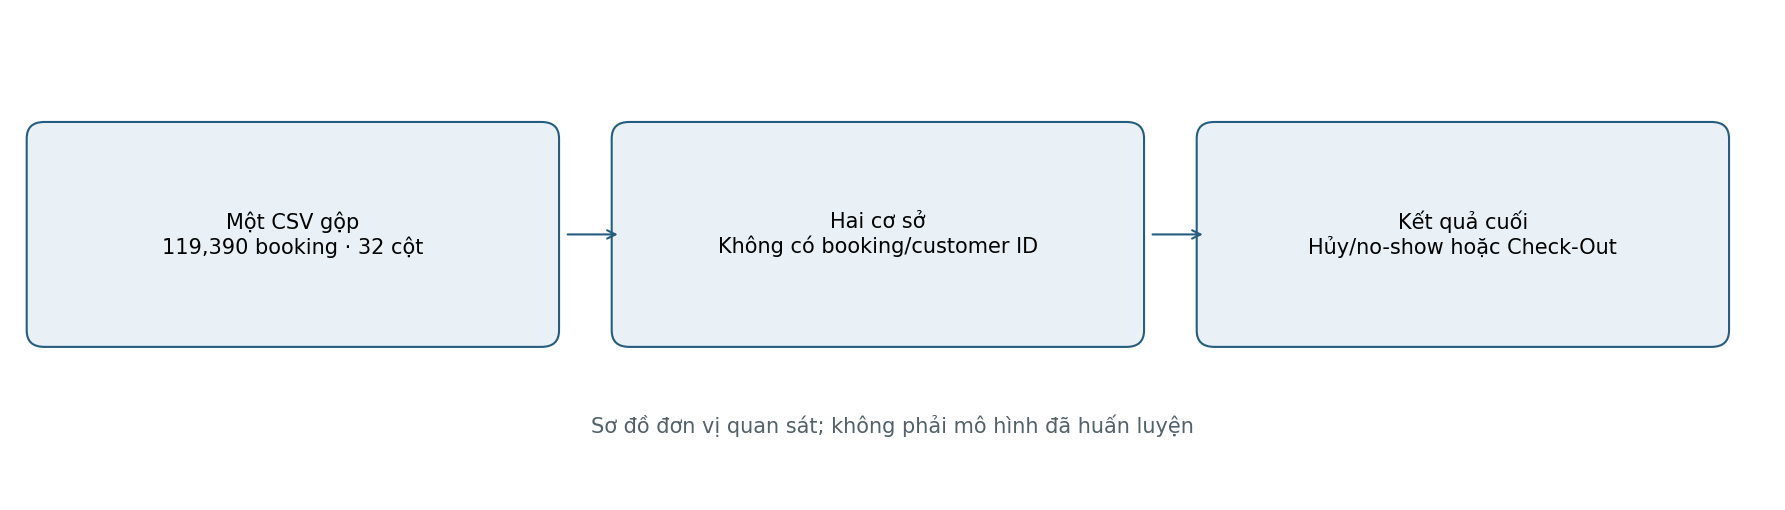

**Quan sát:** mỗi booking có một kết quả cuối, nhưng không có khóa booking/khách hàng để xác minh dòng trùng.

**Phạm vi và cách đọc:** sơ đồ cấu trúc dữ liệu raw hiện có, không biểu diễn quan hệ nhân quả.

### Nguồn gốc và phạm vi thu thập

Nguồn công bố: [trang dữ liệu/nghiên cứu gốc](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/). [Giấy phép/điều khoản và trang phân phối](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand). Thông tin nào chưa được lưu hoặc chưa xác minh được được ghi rõ, không điền bằng giả định.

**Thông tin nguồn và phiên bản**

| Nội dung | Mô tả |
| --- | --- |
| Tên / nơi công bố | Nuno Antonio, Ana de Almeida, Luis Nunes — Data in Brief; bản CSV gộp được phổ biến qua Kaggle |
| Năm công bố | 2018 online; Data in Brief tập 22, 2019 |
| Mục đích thu thập/công bố | Trích xuất PMS để nghiên cứu nhu cầu và kết quả hủy booking ở hai khách sạn Bồ Đào Nha. |
| Cách thu thập / quần thể | Dữ liệu vận hành PMS/SQL và booking change log; hai cơ sở ở Algarve và Lisbon. Không phải mẫu ngẫu nhiên toàn ngành. |
| Thời gian bao phủ quan sát được | Arrival 2015-07-01–2017-08-31 |
| Ngày tải raw | Chưa được ghi lại; không dùng mtime/ctime để thay ngày tải |
| Quy mô bảng train/chính | 119,390 dòng × 32 cột thô |
| Dung lượng mọi CSV của bộ hiện có | 16,855,599 byte = 16.07 MiB; gồm cả bảng phụ/benchmark nếu có |
| Phiên bản local | Nhận diện bằng tên file, bytes, số dòng và SHA-256 tại phụ lục |
| Giấy phép / điều khoản | Bài báo nguồn ghi CC BY (4.0). Nguồn tải/phiên bản của chính bản CSV gộp trên máy chưa được ghi lại; không suy giấy phép CSV chỉ từ giấy phép bài báo. |

### Bối cảnh, quần thể và câu hỏi phân tích

Dữ liệu hiện có gồm **119,390 booking, 32 cột**, từ City Hotel và Resort Hotel. Mỗi dòng là một booking, không phải một khách hàng duy nhất. Không có booking ID hoặc customer ID để xác nhận danh tính, lịch sử khách hoặc nguyên nhân các dòng trùng.

**Bài toán phù hợp:** xác suất một booking có kết quả hủy/no-show. Không đồng nhất việc hủy một booking với customer churn. Mốc dự đoán (lúc tạo booking hay trước ngày đến) và tập booking còn có thể can thiệp chưa được xác lập; báo cáo chỉ đánh giá tính phù hợp dữ liệu, không ước lượng xác suất bằng mô hình.

Các câu hỏi EDA: nhãn thực sự gồm hành vi nào; khác biệt giữa hai khách sạn; mối liên hệ giữa nhãn và kênh/lead time; tác động của trùng lặp; độ phủ thời gian; biến nào tiết lộ kết quả hoặc chưa chứng minh có sẵn tại thời điểm dự đoán.

Nguồn nghiệp vụ: [Antonio, de Almeida & Nunes — Hotel booking demand datasets](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/). Nguồn mô tả hai khách sạn tại Bồ Đào Nha và mốc trích xuất gắn với ngày trước ngày đến. Bản CSV trong dự án có thêm cột `hotel` để phân biệt hai cơ sở. Không suy rộng trực tiếp sang toàn ngành hoặc thị trường Việt Nam.

In [5]:
eda.show_section(report, 'overview')

## 3. Chất lượng dữ liệu

### Chất lượng dữ liệu và định nghĩa nhãn

`is_canceled=1` có **44,224 booking (37.04%)**. Bảng chéo xác nhận nhãn này gồm cả `Canceled` và `No-Show`; nhãn 0 là `Check-Out`. Vì vậy tên mục tiêu trong báo cáo là **hủy/no-show**, thay vì chỉ hủy chủ động.

`reservation_status` tiết lộ hoàn toàn nhãn. `reservation_status_date` là ngày trạng thái cuối, cũng thuộc thông tin kết quả. Hai cột chỉ được dùng để hiểu dữ liệu.

`company`/`agent` có nhiều NULL; theo nghiên cứu gốc, NULL ở các cột này có thể nghĩa **không áp dụng**. Không coi các ID này là số liên tục hay mặc định thay NULL bằng trung vị. Với `children`/`country`, nguyên nhân thiếu chưa được xác minh từ CSV.

Nếu giả định loại tất cả dòng trùng, tỷ lệ nhãn 1 đổi từ **37.04%** thành **27.49%**. Đây là độ nhạy đáng kể, không phải chỉ định phải deduplicate. Không có khóa booking nên chưa phân biệt được lỗi lặp với các booking thật có cùng thuộc tính. Các dòng gốc vẫn được giữ nguyên.

ADR âm/cao hoặc booking 0 đêm/0 khách là trường hợp cần xác minh. CSV không chứng minh nguyên nhân là hoàn tiền, voucher hay nhập sai; không clipping hay xóa trong báo cáo.

**Kiểm tra bất thường (các điều kiện có thể chồng lặp)**

| Kiểm tra | Số booking | Trong toàn bộ booking (%) |
| --- | --- | --- |
| Dòng trùng hoàn toàn; giữ lần xuất hiện đầu để đếm | 31,994 | 26.7979 |
| Tổng số khách bằng 0 sau quy ước missing children=0 chỉ để kiểm tra | 180 | 0.1508 |
| Tổng số đêm bằng 0 | 715 | 0.5989 |
| ADR âm | 1 | 0.0008 |
| ADR bằng 0 | 1,959 | 1.6408 |
| ADR > 1.000 (ngưỡng kiểm tra, không phải kết luận lỗi) | 1 | 0.0008 |
| Ngày đến không parse được | 0 | 0 |
| Nhãn ngoài {0,1} hoặc thiếu | 0 | 0 |

**Trạng thái cuối × nhãn**

| reservation_status | 0 | 1 |
| --- | --- | --- |
| Canceled | 0 | 43,017 |
| Check-Out | 75,166 | 0 |
| No-Show | 0 | 1,207 |

... (2 outputs left out)

### Missing có quy luật hay không?

Heatmap chọn tối đa 12 cột có NA. Chọn dòng để hiển thị với seed=42 và sắp theo pattern; bảng tỷ lệ theo nhóm dùng quần thể phân tích công bố, không chỉ các dòng hiển thị.

**Missing (%) theo is_canceled; toàn bộ booking HOTEL**

| is_canceled | company | agent | country | children |
| --- | --- | --- | --- | --- |
| 0 | 92.5418 | 16.3771 | 0.5601 | 0 |
| 1 | 97.3069 | 9.1127 | 0.1515 | 0.009 |

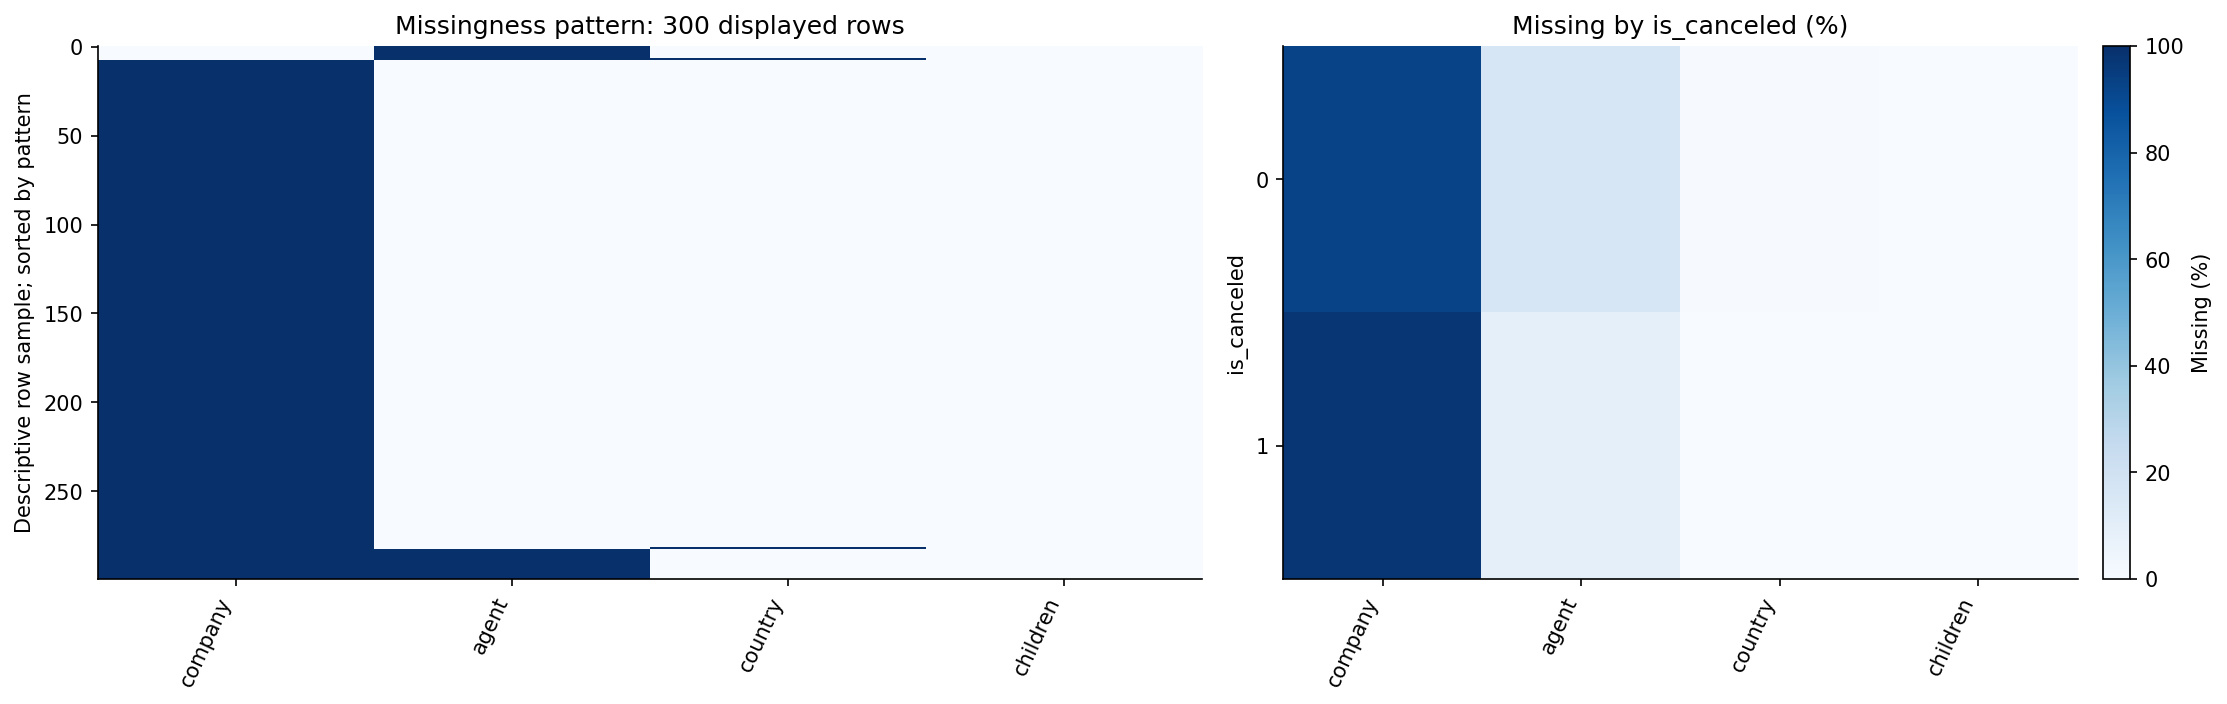

**Quan sát:** company thiếu 94.31% trong toàn bộ booking HOTEL; chênh lệch missing lớn nhất giữa các nhóm is_canceled là 7.26 điểm phần trăm ở agent. Ô xanh là NA. Mẫu dòng hiển thị dùng seed=42; việc sắp theo pattern chỉ để nhìn cụm thiếu, không phải thứ tự thời gian. Các khác biệt này không đủ kết luận cơ chế MCAR/MAR/MNAR.

**Phạm vi và cách đọc:** Bảng tổng hợp dùng toàn bộ dữ liệu; hình pattern tối đa 300 dòng seed=42. Không xác định cơ chế MCAR/MAR/MNAR.

### Ngoại lai: lượng hóa và phân biệt quy tắc với kết luận lỗi

Quy tắc 1,5×IQR chỉ gắn cờ để kiểm tra, không tự chứng minh lỗi. Mẫu số là số giá trị không thiếu của từng cột; bảng giữ rõ quần thể và trường hợp IQR=0.

**Hàng rào IQR trên dữ liệu công bố**

| Cột gốc | Quần thể/cách tính | nonnull_n | q1 | q3 | iqr | lower_fence | upper_fence | flagged_n | flagged_pct_nonnull | iqr_zero |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| adr | toàn bộ booking HOTEL | 119,390 | 69.29 | 126 | 56.71 | -15.775 | 211.065 | 3,793 | 3.177 | 0 |
| lead_time | toàn bộ booking HOTEL | 119,390 | 18 | 160 | 142 | -195 | 373 | 3,005 | 2.517 | 0 |
| adults | toàn bộ booking HOTEL | 119,390 | 2 | 2 | 0 | 2 | 2 | 29,710 | 24.8848 | 1 |
| children | toàn bộ booking HOTEL | 119,386 | 0 | 0 | 0 | 0 | 0 | 8,590 | 7.1951 | 1 |
| booking_changes | toàn bộ booking HOTEL | 119,390 | 0 | 0 | 0 | 0 | 0 | 18,076 | 15.1403 | 1 |

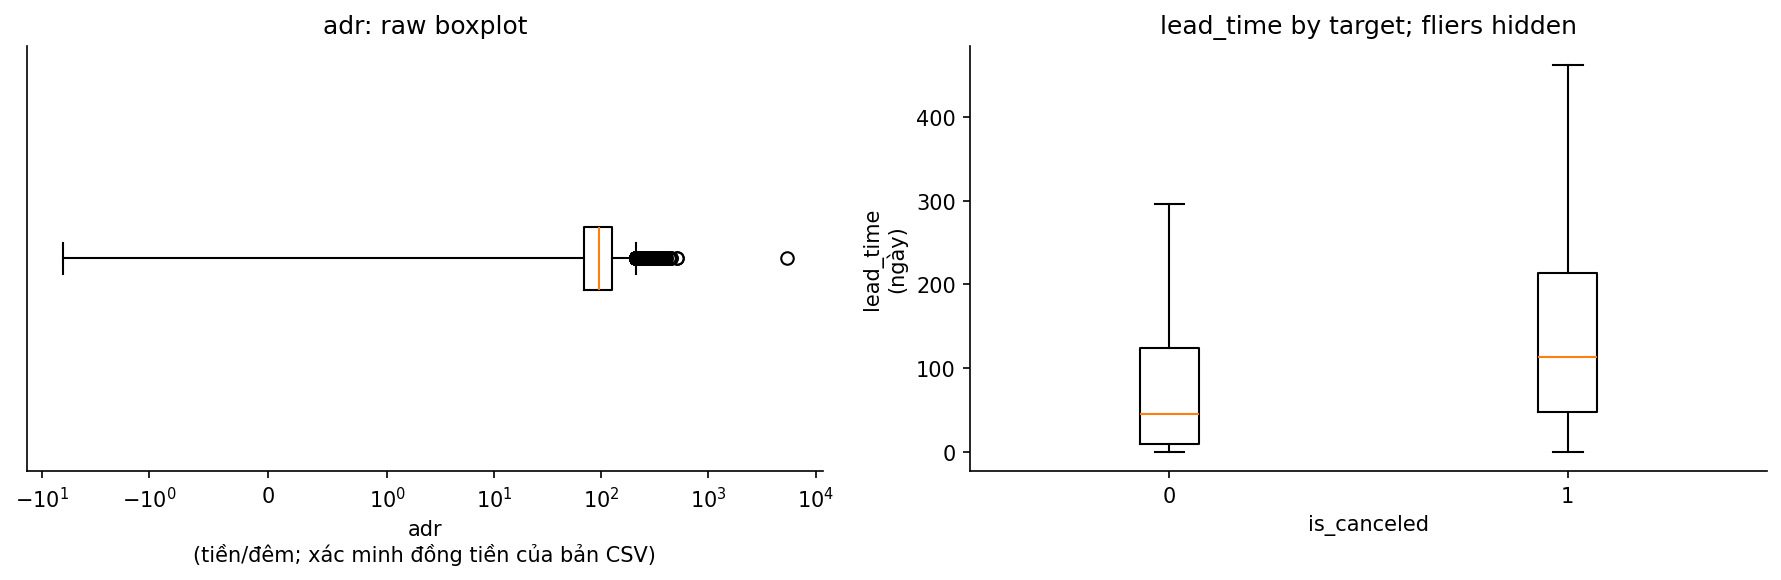

**Quan sát:** theo hàng rào Q1−1,5×IQR và Q3+1,5×IQR, adr có 3,793/119,390 giá trị bị gắn cờ (3.18%) trong toàn bộ booking HOTEL; đây là bất thường thống kê, chưa phải lỗi nhập liệu. Median lead_time theo nhãn: 0=45.00, 1=113.00. Boxplot bên phải ẩn các điểm ngoài whisker để đọc vùng giữa, không xóa chúng khỏi bảng hay raw. Đơn vị xem từ điển; IQR=0 ở biến rời rạc có thể gắn cờ nhiều giá trị thật. Trục x boxplot raw dùng symlog; hàng rào IQR vẫn tính trên giá trị raw, không phải log.

**Phạm vi và cách đọc:** Quần thể, mẫu số và cửa sổ hiển thị ghi trên hình và bảng cạnh hình. Giữ nguyên giá trị raw; nhóm nhỏ cần đọc thận trọng.

### Vai trò dữ liệu trong thiết kế chính

Bảng quyết định chi tiết từng cột nằm trong phụ lục. Đầu vào của mọi mô hình phải qua kiểm tra t0 trước khi so sánh chất lượng.

**Kiểm kê vai trò**

| Quyết định | Số cột |
| --- | --- |
| Ứng viên có điều kiện | 22 |
| Nhãn | 1 |
| Chặn khi thiếu lịch sử | 7 |
| Chặn đầu vào | 2 |

In [6]:
eda.show_section(report, 'quality_main')

## 4. Phân tích đơn biến

### Phân phối đơn biến và mức độ bao phủ

Thống kê định lượng dùng toàn bộ dữ liệu, bỏ NA riêng ở từng cột. p1/p95/p99 cho thấy phần đuôi mà mean/median có thể che khuất. Bảng category hiển thị top 8 mỗi biến, tỷ lệ luôn chia cho toàn bộ booking (kể cả missing), nên tổng top 8 có thể nhỏ hơn 100%. ADR trên biểu đồ chỉ giới hạn vùng nhìn; dữ liệu và thống kê không bị cắt.

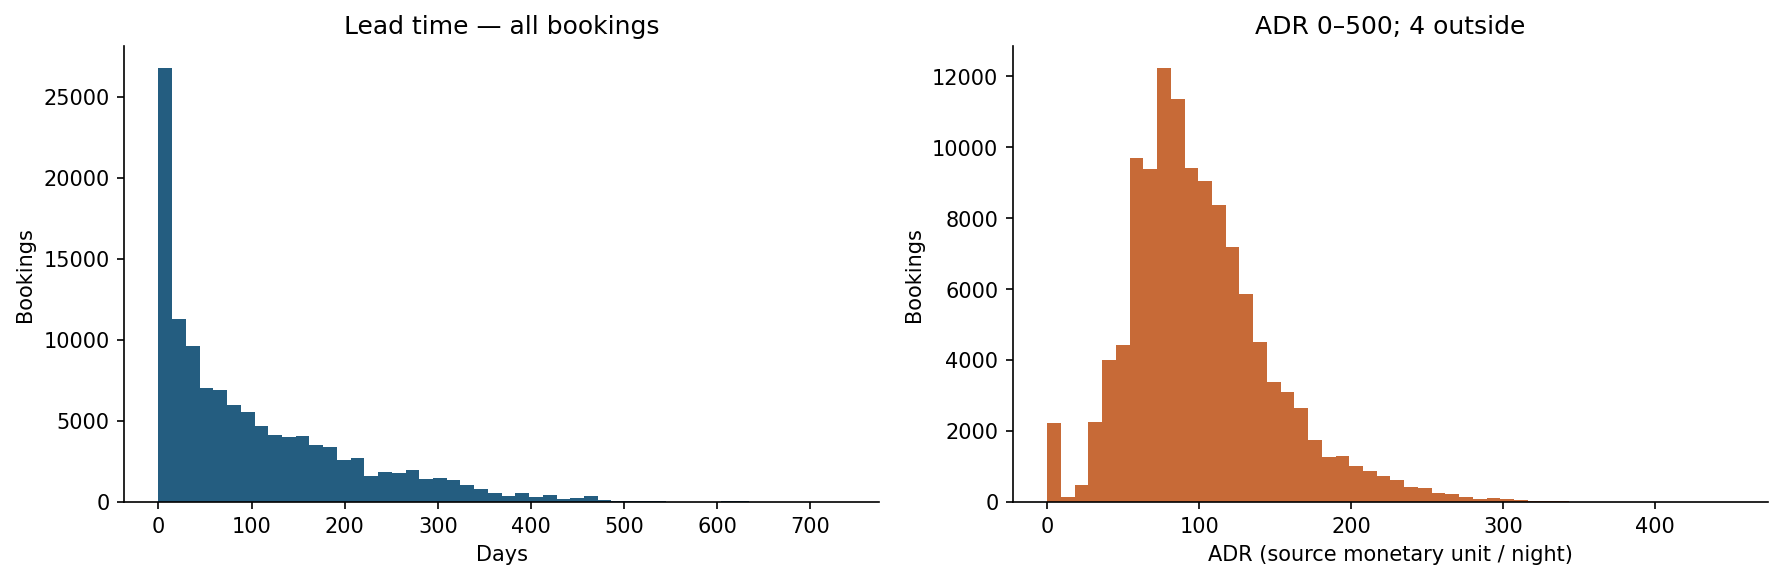

**Quan sát:** lead_time có median 69 ngày so với mean 104.01, thể hiện đuôi phải; ADR median 94.58, max 5400.00. Biểu đồ ADR chỉ vẽ 0–500, có 4 dòng ngoài vùng nhìn; thống kê vẫn giữ tất cả.

**Phạm vi và cách đọc:** Quần thể, mẫu số và cửa sổ hiển thị ghi trên hình và bảng cạnh hình. Giữ nguyên giá trị raw; nhóm nhỏ cần đọc thận trọng.

### Biến phân loại và nhãn

Biểu đồ hiển thị top 8 nhóm theo số lượng; bảng kiểm kê giữ cả các nhóm nhỏ. Nhóm hiếm được báo với ngưỡng mô tả n<100, chưa gộp category.

**Tần suất đầy đủ của market_segment**

| market_segment | Số booking | Số nhãn 1 |
| --- | --- | --- |
| Online TA | 56,477 | 20,739 |
| Offline TA/TO | 24,219 | 8,311 |
| Groups | 19,811 | 12,097 |
| Direct | 12,606 | 1,934 |
| Corporate | 5,295 | 992 |
| Complementary | 743 | 97 |
| Aviation | 237 | 52 |
| Undefined | 2 | 2 |

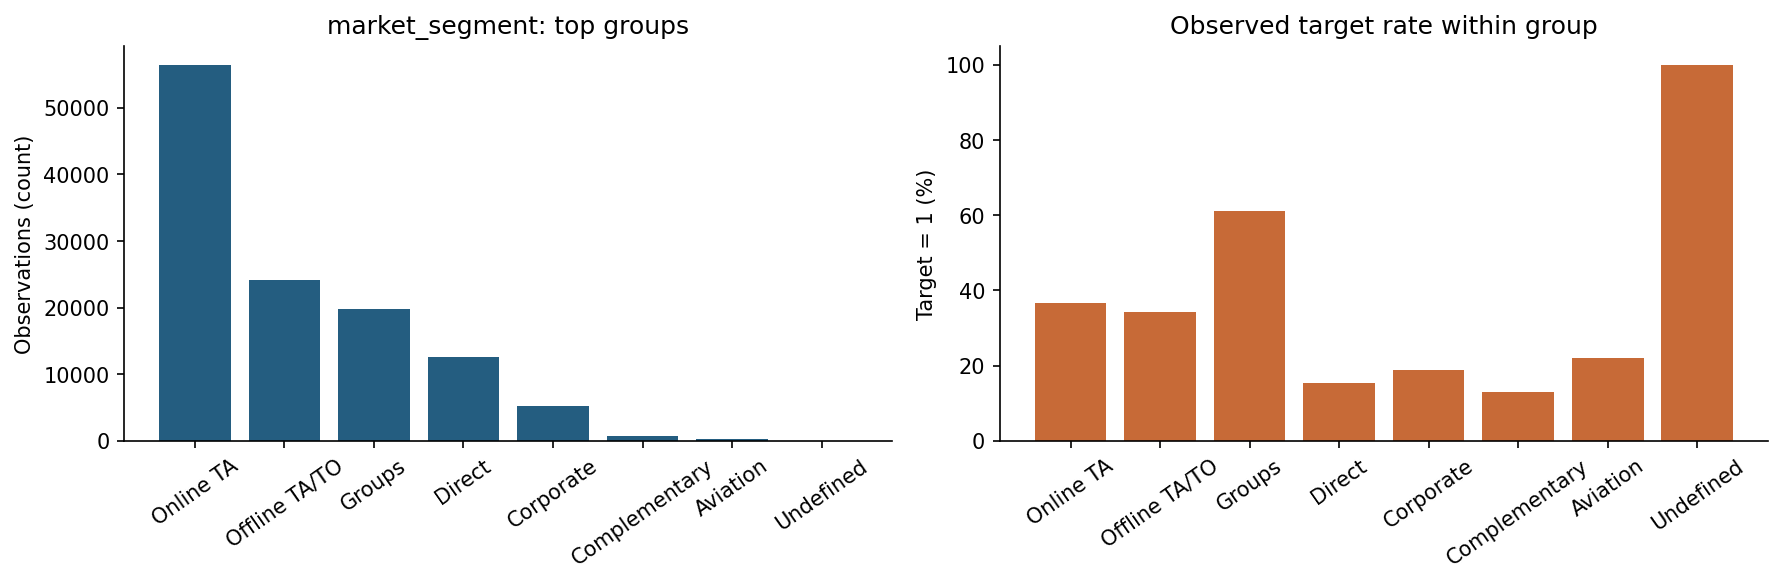

**Quan sát:** market_segment có 8 nhóm (không có NA); 1 nhóm dưới 100 quan sát. Nhóm lớn nhất Online TA có 56,477 quan sát, tỷ lệ nhãn 1 là 36.72%. Hai trục trả lời số lượng nhóm và tỷ lệ bên trong nhóm, không dùng lẫn mẫu số; phân tầng cohort được trình bày tại phần đa biến.

**Phạm vi và cách đọc:** Quần thể, mẫu số và cửa sổ hiển thị ghi trên hình và bảng cạnh hình. Giữ nguyên giá trị raw; nhóm nhỏ cần đọc thận trọng.

In [7]:
eda.show_section(report, 'univariate')

## 5. Nhãn, liên hệ đa biến, thời gian và nhóm con

### Độ mạnh liên hệ và độ nhạy với trùng lặp

Khảo sát đủ 29 cột ngoài nhãn và hai cột trạng thái cuối. Bảng chính chọn chín biến để đọc; phụ lục giữ đầy đủ, gồm kết quả riêng từng cơ sở. Đây là liên hệ đơn biến, chưa phải chất lượng dự đoán. Đặt cọc, thay đổi booking và yêu cầu bổ sung cần kiểm tra thời điểm ghi nhận trước khi thử mô hình.

**Các liên hệ chính**

| Biến | Thước đo | Liên hệ · raw | Liên hệ · bỏ trùng giả định | Liên hệ · City | Liên hệ · Resort | Cỡ mẫu sử dụng |
| --- | --- | --- | --- | --- | --- | --- |
| hotel | Cramér V | 0.1365 | 0.0716 | — | — | 119,390 |
| lead_time | Rank-biserial | 0.3785 | 0.2926 | 0.3805 | 0.3577 | 119,390 |
| market_segment | Cramér V | 0.2668 | 0.221 | 0.2922 | 0.2528 | 119,390 |
| previous_cancellations | Rank-biserial | 0.1268 | 0.039 | 0.143 | 0.0772 | 119,390 |
| booking_changes | Rank-biserial | -0.1378 | -0.1082 | -0.1339 | -0.1263 | 119,390 |
| deposit_type | Cramér V | 0.4815 | 0.1651 | 0.5185 | 0.3228 | 119,390 |
| customer_type | Cramér V | 0.1364 | 0.1271 | 0.1529 | 0.1412 | 119,390 |
| adr | Rank-biserial | 0.0608 | 0.1847 | -0.0366 | 0.1415 | 119,390 |
| total_of_special_requests | Rank-biserial | -0.2717 | -0.1507 | -0.3307 | -0.126 | 119,390 |

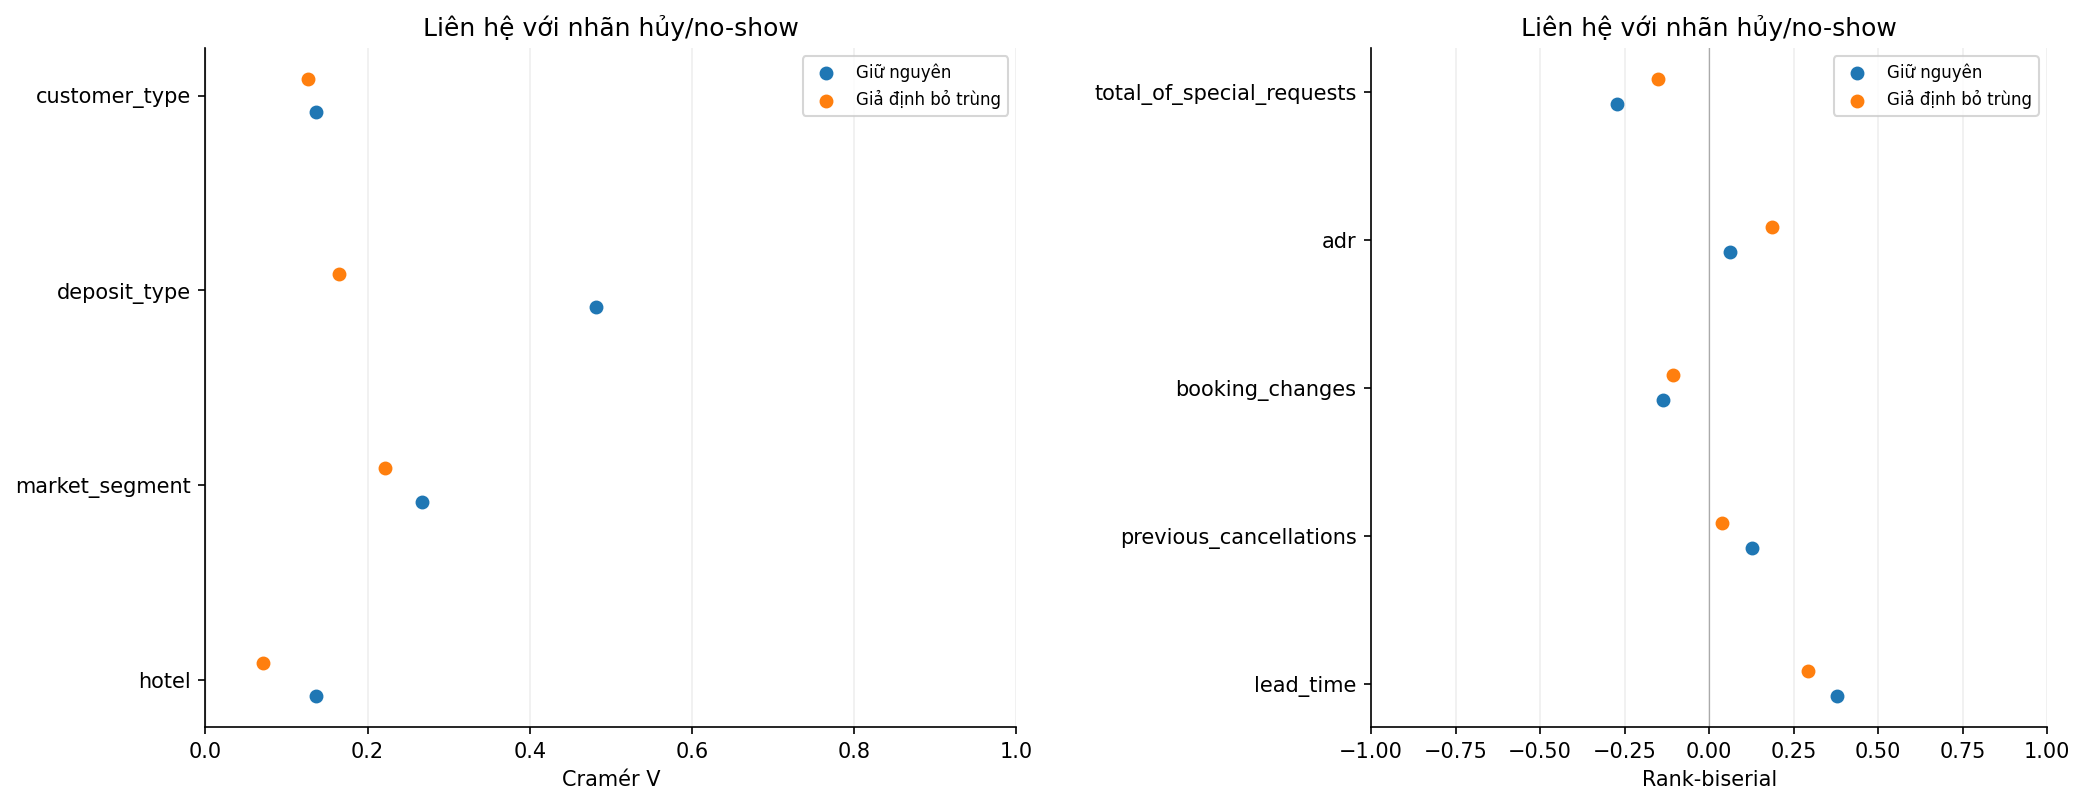

**Quan sát:** bảng cạnh hình đối chiếu liên hệ trước và sau giả định bỏ dòng trùng; độ nhạy cần được xét trước lựa chọn mô hình.

**Phạm vi và cách đọc:** toàn bộ booking trong từng kịch bản; biến phân loại gồm missing, biến số bỏ NA riêng từng cột. Hai thước đo có trục riêng. Cột có liên hệ mạnh vẫn bị chặn nếu chưa có bằng chứng tại t0.

### Tách khác biệt cơ cấu khách khỏi chênh lệch hai cơ sở

Dùng cùng trọng số phân khúc thị trường cho hai khách sạn trên phần giao có ít nhất 100 booking mỗi cơ sở. Trọng số tỷ lệ với tổng booking của cả hai cơ sở trong phần giao. Chênh lệch City − Resort sau chuẩn hóa là 11.69 điểm phần trăm. Đây là chuẩn hóa mô tả một biến; chưa điều chỉnh quốc gia, thời gian, đặt cọc hoặc khách lặp, nên không suy ra tác động của loại khách sạn.

**Raw và tỷ lệ cùng cơ cấu phân khúc**

| hotel | Số booking | Tỷ lệ nhãn 1 (%) | Booking trong phần giao | Độ phủ phần giao (%) | Tỷ lệ cùng cơ cấu (%) |
| --- | --- | --- | --- | --- | --- |
| City Hotel | 79,330 | 41.727 | 79,091 | 99.6987 | 40.7428 |
| Resort Hotel | 40,060 | 27.7634 | 40,060 | 100 | 29.0527 |

### Mối liên hệ với nhãn và tương tác phân khúc

Mẫu số là booking trong từng nhóm; không phải tỷ trọng nhóm trong toàn dữ liệu. Các khoảng Wilson 95% là mô tả tham khảo dưới giả định quan sát độc lập; duplicate, booking theo đoàn và khách lặp có thể làm mức bất định thực tế lớn hơn. Nhóm dưới 100 quan sát được gắn cờ, không xếp hạng chắc chắn. Các liên hệ không phải tác động nhân quả của kênh, đặt cọc hoặc thời gian đặt trước. Bảng hotel × market_segment giúp kiểm tra việc khác cơ cấu khách giữa hai cơ sở.

**Tỷ lệ nhãn 1 theo hotel**

| hotel | Số booking | Số nhãn 1 | Tỷ lệ nhãn 1 (%) | Cận dưới 95% (%) | Cận trên 95% (%) | Nhóm dưới 100 |
| --- | --- | --- | --- | --- | --- | --- |
| City Hotel | 79,330 | 33,102 | 41.727 | 41.3842 | 42.0705 | 0 |
| Resort Hotel | 40,060 | 11,122 | 27.7634 | 27.327 | 28.204 | 0 |

**Lead time — nhóm chỉ phục vụ thống kê EDA**

| lead_time_group | Số booking | Số nhãn 1 | Tỷ lệ nhãn 1 (%) | Cận dưới 95% (%) | Cận trên 95% (%) | Nhóm dưới 100 |
| --- | --- | --- | --- | --- | --- | --- |
| 31–90 | 29,553 | 11,141 | 37.6984 | 37.1475 | 38.2525 | 0 |
| 91–180 | 26,439 | 11,821 | 44.7105 | 44.112 | 45.3105 | 0 |
| 181–365 | 21,544 | 11,947 | 55.454 | 54.7894 | 56.1166 | 0 |
| 8–30 | 18,960 | 5,283 | 27.8639 | 27.2303 | 28.5065 | 0 |
| 1–7 | 13,401 | 1,472 | 10.9843 | 10.466 | 11.5249 | 0 |
| 0 | 6,345 | 430 | 6.777 | 6.1843 | 7.422 | 0 |
| >365 | 3,148 | 2,130 | 67.662 | 66.0073 | 69.2737 | 0 |

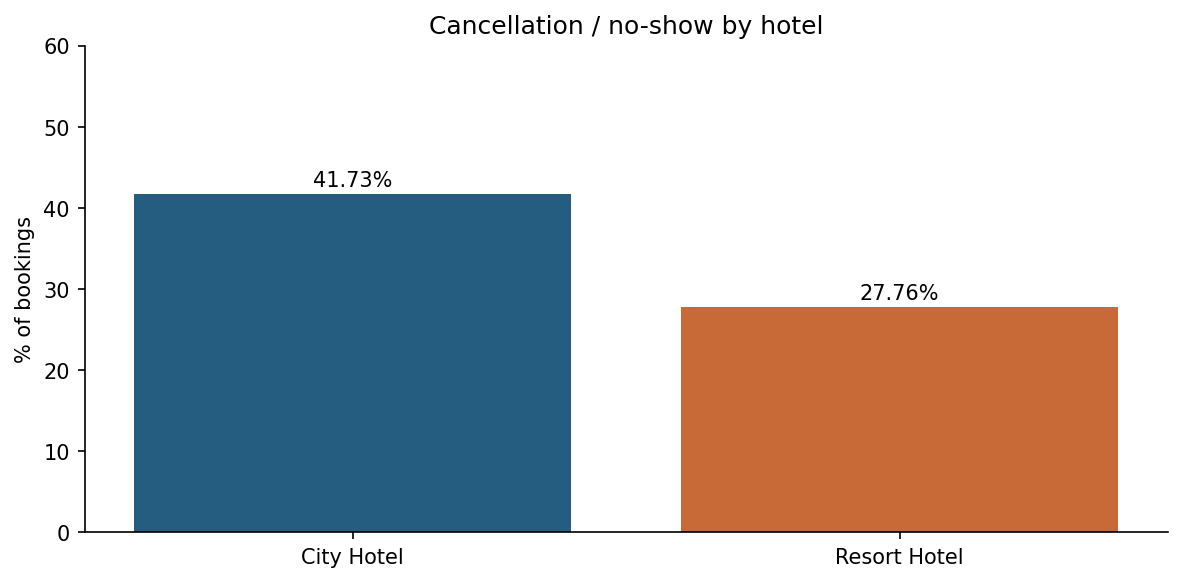

**Quan sát:** tỷ lệ hủy/no-show City Hotel 41.73% và Resort Hotel 27.76%, chênh 13.96 điểm phần trăm. Đây là khác biệt giữa hai cơ sở có cơ cấu khách khác nhau, không phải tác động riêng của loại khách sạn.

**Phạm vi và cách đọc:** Quần thể, mẫu số và cửa sổ hiển thị ghi trên hình và bảng cạnh hình. Giữ nguyên giá trị raw; nhóm nhỏ cần đọc thận trọng.

### Tương quan, tương tác và chồng lặp thông tin

Ma trận Spearman dùng từng cặp không thiếu. Scatter lấy tối đa 4.000 điểm seed=42 để tránh che lấp, giữ nhãn trục và đơn vị. Chưa thực hiện kiểm định nhiều giả thuyết hay kết luận nhân quả; cấu trúc phụ thuộc quan sát và kích thước hiệu ứng cần được xét trước p-value.

**Ma trận Spearman**

| Cột gốc | lead_time | adr | stays_in_week_nights | stays_in_weekend_nights | adults | children | booking_changes | total_of_special_requests |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| lead_time | 1 | 0.015 | 0.2963 | 0.1621 | 0.1922 | -0.0162 | -0.0078 | -0.0741 |
| adr | 0.015 | 1 | 0.0938 | 0.0514 | 0.2798 | 0.2655 | 0.0052 | 0.1964 |
| stays_in_week_nights | 0.2963 | 0.0938 | 1 | 0.2381 | 0.153 | 0.0543 | 0.0645 | 0.0762 |
| stays_in_weekend_nights | 0.1621 | 0.0514 | 0.2381 | 1 | 0.1268 | 0.0528 | 0.0404 | 0.0794 |
| adults | 0.1922 | 0.2798 | 0.153 | 0.1268 | 1 | 0.0721 | -0.085 | 0.1616 |
| children | -0.0162 | 0.2655 | 0.0543 | 0.0528 | 0.0721 | 1 | 0.0659 | 0.0957 |
| booking_changes | -0.0078 | 0.0052 | 0.0645 | 0.0404 | -0.085 | 0.0659 | 1 | 0.0419 |
| total_of_special_requests | -0.0741 | 0.1964 | 0.0762 | 0.0794 | 0.1616 | 0.0957 | 0.0419 | 1 |

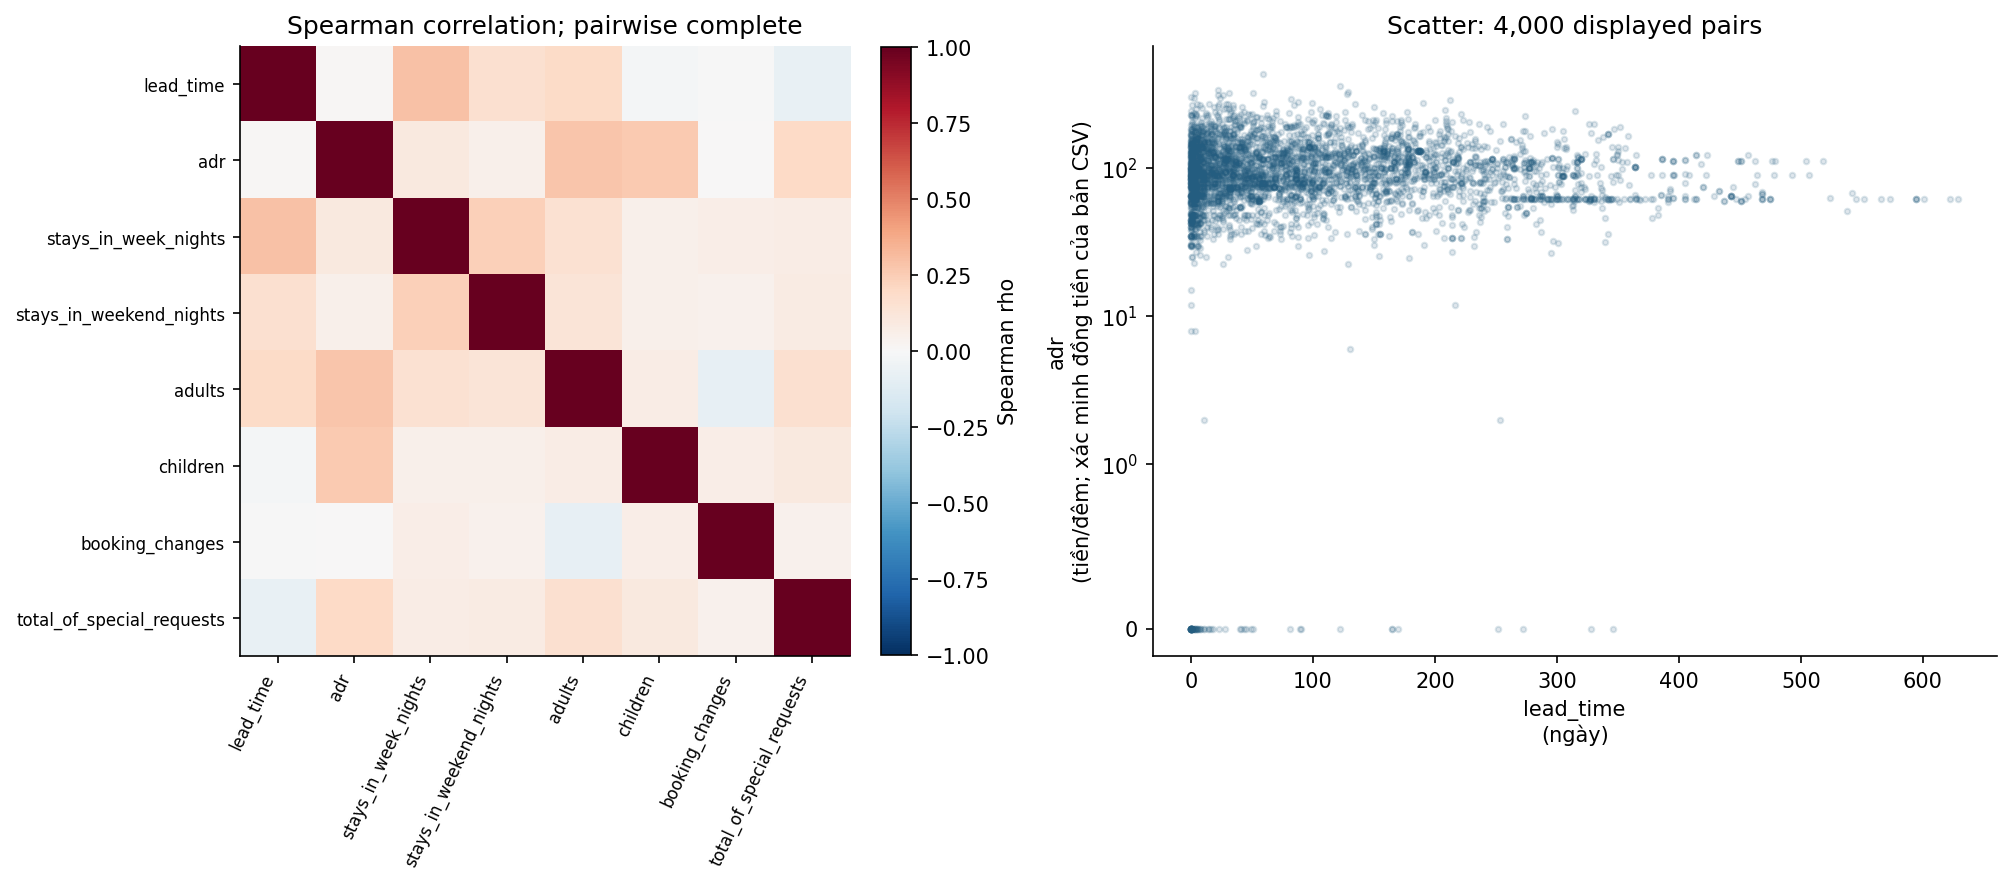

**Quan sát:** trong toàn bộ booking HOTEL, cặp có |rho| lớn nhất của ma trận công bố là lead_time–stays_in_week_nights (rho=0.296); riêng lead_time–adr có rho=0.015. Scatter chỉ hiển thị tối đa 4.000 cặp không thiếu, seed=42; đơn vị từng biến xem từ điển. Heatmap dùng dữ liệu toàn bộ booking HOTEL, không chỉ các điểm scatter. Tương quan cao là dấu hiệu chồng lặp để kiểm tra, không tự chứng minh đa cộng tuyến tuyến tính hoặc quan hệ nhân quả. Trục y của scatter dùng thang symlog để đọc đuôi dài; giá trị raw không bị biến đổi/lưu lại.

**Phạm vi và cách đọc:** Tương quan dùng từng cặp không thiếu; scatter tối đa 4.000 điểm chỉ để hiển thị.

### Thời gian, mùa vụ và giới hạn đánh giá

Ngày đến parse được nằm trong **2015-07-01–2017-08-31**. Đây là thời gian ngày đến, không phải thời gian tạo booking. Các tháng đầu/cuối không bao phủ đủ năm, nên không gộp số booking theo tên tháng rồi kết luận mùa vụ. Đồ thị dưới giữ năm–tháng và tách hai khách sạn. Chưa đủ cơ sở để chọn một cách chia tập cuối cùng: cần định nghĩa t0, nhãn đã trưởng thành và đối tượng còn có thể can thiệp; nếu đánh giá tương lai thì ưu tiên giữ trật tự thời gian, đồng thời kiểm tra duplicate qua các tập.

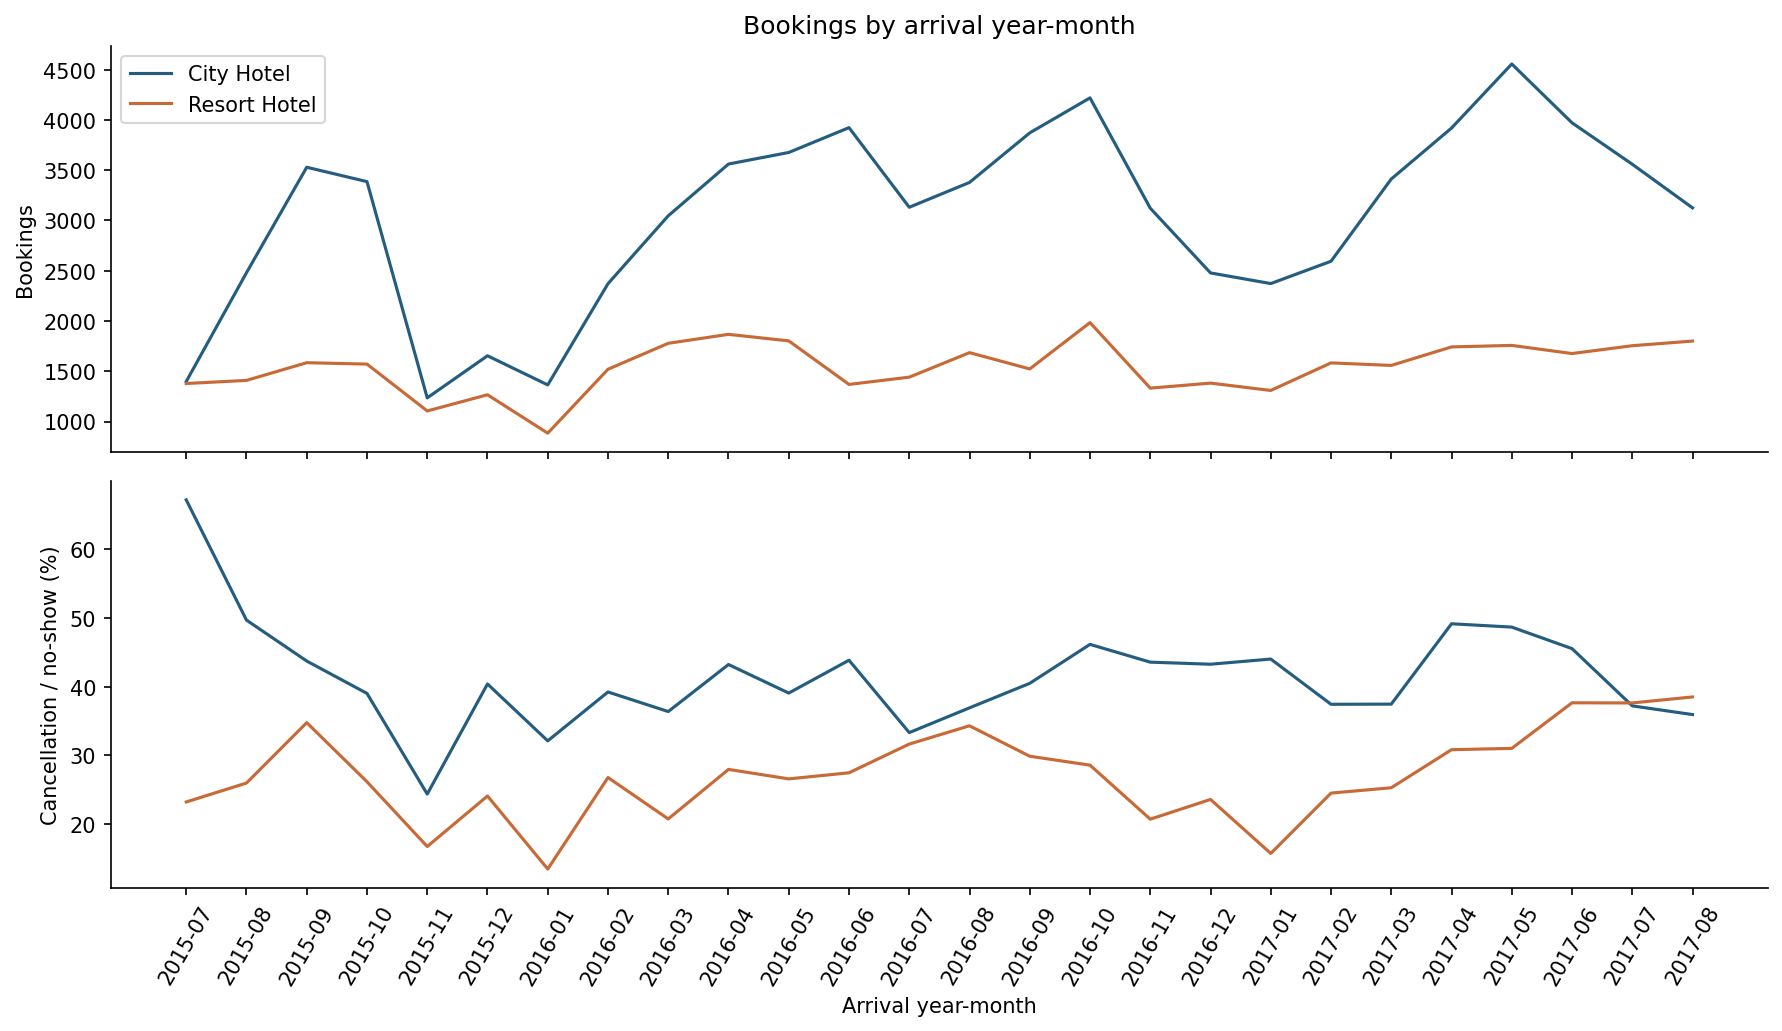

**Quan sát:** tỷ lệ nhãn theo tháng đến gộp hai cơ sở dao động 20.77–45.35%; số booking và tỷ lệ hủy thay đổi theo thời gian và khách sạn. Các tháng có số năm bao phủ khác nhau, nên chưa kết luận mùa vụ lặp ổn định chỉ từ đường này.

**Phạm vi và cách đọc:** Số lượng và tỷ lệ theo năm–tháng; tháng đầu/cuối có thể thiếu ngày. Không kết luận mùa vụ chỉ từ số tháng gộp.

In [8]:
eda.show_section(report, 'multivariate_main')

## 6. Tổng hợp giới hạn và mức độ phù hợp

In [9]:
eda.show_section(report, 'risks')

Tách điều đã quan sát khỏi nguyên nhân chưa được chứng minh. Không diễn giải chênh lệch nhóm thành đặc điểm cố hữu của giới tính/tuổi/quốc gia và không thực hiện nhận diện lại cá nhân.

**Rủi ro và giới hạn sử dụng**

| Vấn đề | Bằng chứng hoặc giới hạn |
| --- | --- |
| Quyền riêng tư | Nguồn đã loại thông tin định danh trực tiếp; không có customer/booking ID để liên kết tin cậy. Quốc gia, ngày đến, cấu trúc đoàn vẫn là thông tin có thể kết hợp. |
| Quần thể | Hai khách sạn ở Bồ Đào Nha và một giai đoạn lịch sử, không đại diện cho mọi khách sạn hoặc thị trường Việt Nam. |
| Phụ thuộc / bias | Booking theo đoàn hoặc khách lặp không nhận diện được; duplicate có thể làm khoảng tin cậy quá hẹp. |
| Rò rỉ | Trạng thái cuối và ngày trạng thái là kết quả; các biến cập nhật theo vòng đời cần lịch sử tại t0. |
| Đồng ý / quyền sử dụng | CSV không có biểu mẫu đồng ý hay hồ sơ pháp lý thu thập. Không suy dữ liệu công khai = đồng ý cho mọi mục đích; đọc điều khoản nguồn, không tự gán giấy phép mở. |
| Giới hạn suy luận | EDA là mô tả, không phải kiểm định tác động can thiệp. Khoảng Wilson nếu có chỉ theo giả định độc lập; chưa đánh giá chất lượng mô hình hoặc tính công bằng của mô hình. |

### Kết luận và hướng nghiên cứu

### Kết luận và câu hỏi còn mở

**Kết luận đã kiểm chứng:** nhãn 1 chiếm 37.04%, gồm hủy và no-show; có 31,994 dòng trùng hoàn toàn; tỷ lệ thay đổi mạnh theo giả định bỏ trùng; hai cơ sở và các kênh có cơ cấu khác nhau. Thông tin trạng thái cuối không thể là đầu vào dự đoán.

**Mức độ phù hợp:** tốt cho nghiên cứu cancellation/no-show ở cấp booking. Chưa đủ để mô tả churn ở cấp khách hàng hoặc mô phỏng chấm điểm ngay lúc tạo booking một cách đáng tin cậy.

**Cần xác minh trước giai đoạn tiếp theo:** (1) thời điểm chấm điểm và tập booking còn hiệu lực; (2) lịch sử giá trị tại t0 cho từng biến, nhất là assigned_room_type, booking_changes, deposit_type, ADR và yêu cầu bổ sung; (3) định danh booking/nhóm để giải thích trùng; (4) ý nghĩa các booking 0 khách/0 đêm và ADR bất thường; (5) phạm vi áp dụng ngoài hai khách sạn.

Không xóa dòng, impute, clipping, encoding, tạo feature hoặc train model trong báo cáo này. Các phân nhóm ngày/tháng và lead time chỉ là bảng thống kê EDA; không được xuất thành tập huấn luyện.

... (4 outputs left out)

### Câu hỏi mở và cách xác minh

Đã đọc [nghiên cứu gốc](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/) ngày 2026-11-02; chưa có lịch sử PMS hoặc hồ sơ ETL của bản gộp local. Vai trò trong bảng là đề xuất theo dõi, chưa phải người đã nhận việc. Ngày tải/mã phiên bản chưa được ghi nhận; giữ SHA-256 để định danh bản local.

**Danh mục xác minh**

| Câu hỏi | Thông tin còn thiếu | Nguồn có thể trả lời | Cách xác minh | Điều kiện kết thúc hoặc quyết định | Vai trò đề xuất | Trạng thái |
| --- | --- | --- | --- | --- | --- | --- |
| H-Q1 · Snapshot | Giá trị từng cột và cờ thiếu tại lúc tạo booking có được lưu? | https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/ | Đối chiếu lịch sử PMS và truy vấn trích xuất theo từng cột | Có snapshot tại t0; nếu chưa có chỉ nghiên cứu liên hệ hồi cứu | Tác giả tổng hợp; người cung cấp dữ liệu xác nhận; người hướng dẫn duyệt phạm vi | Mở · chưa đủ bằng chứng |
| H-Q2 · Dòng trùng | Các dòng giống nhau là booking thật, đoàn hay lỗi sao chép? | Người cung cấp CSV gộp; khóa booking từ PMS | Đối chiếu booking ID và log ETL; không suy từ thuộc tính giống nhau | Xác nhận đơn vị; chốt chính sách trùng và nhóm qua các tập | Tác giả tổng hợp; người cung cấp dữ liệu xác nhận; người hướng dẫn duyệt phạm vi | Mở · chưa đủ bằng chứng |
| H-Q3 · Quần thể và nhãn | Chấm lúc tạo booking hay trước ngày đến, và nhãn có sẵn lúc nào? | https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/ | Xác định booking còn hiệu lực tại t0, mốc hoàn tất và lịch chọn mẫu theo ngày đến | Có quần thể đủ điều kiện và thời gian theo dõi; không dùng booking đã hủy làm đối tượng can thiệp | Tác giả tổng hợp; người cung cấp dữ liệu xác nhận; người hướng dẫn duyệt phạm vi | Mở · chưa đủ bằng chứng |

## 7. Thuật toán và thiết kế đánh giá đề xuất

### Baseline, mô hình chính và xác suất

Các nhánh dưới đây là đặc tả đề xuất, chưa tạo feature, fit mô hình hoặc hiệu chỉnh. Mọi ứng viên so sánh trên cùng tập thông tin đã được chấp nhận tại t0.

**Nhánh đầu vào**

| Nhánh | Thông tin | Điều kiện |
| --- | --- | --- |
| H0 · Booking tại t0 | Các thuộc tính đã xác nhận lúc tạo booking; không gồm cột bị chặn | Chưa có snapshot, chưa được fit như mô hình vận hành |
| H1 · Mở rộng snapshot | Thêm từng cột cập nhật có lịch sử xác nhận tại mốc dự đoán | Mỗi cột và cờ thiếu cần bằng chứng; không dùng trạng thái cuối |
| Độ nhạy trùng | Giữ raw / giả định bỏ trùng trên cùng thiết kế thời gian | Không tự coi kịch bản bỏ trùng là chân lý; ngăn nhóm giống hệt giao tập |

**Ứng viên và đối chứng**

| Ứng viên | Vai trò | Kiểm soát |
| --- | --- | --- |
| Xác suất hằng | Tỷ lệ hủy/no-show của tập học | Đối chứng xác suất cơ bản |
| Logistic Regression L2 | Hiệu ứng chính và tương tác hotel × segment, lead-time × segment khi hợp lệ | One-hot, spline/biến đổi số và L2 chỉ chọn từ lịch sử phát triển |
| CatBoost | Cùng tập thông tin được phê duyệt với LR | So với LR mạnh nhất gồm tương tác; không dùng mọi cột raw mặc định |
| Sigmoid từ OOF theo thời gian | Áp dụng cùng quy trình cho cả LR và CatBoost | Điểm OOF tạo từ lịch sử cũ, nhãn đã hoàn tất; không học hiệu chỉnh từ điểm trong mẫu |

### Chia theo thời gian và kiểm soát đánh giá

Bảng là kiểm tra tính khả thi theo tháng đến, chưa phải mô phỏng chấm tại lúc tạo booking. Lịch sử chỉ gồm booking có ngày đến trước O và max(ngày đến, ngày trạng thái cuối)+1 ngày ≤ O; không dùng ngày trạng thái làm đầu vào. Các tháng 7, 9, 11/2016 dùng phát triển; tháng 5–6/2017 dự kiến giữ để đánh giá cuối nếu triển khai thí nghiệm. Ngày kết quả trong CSV chỉ là cận kiểm tra lịch sử, chưa xác nhận lúc hệ thống thực sự nhận nhãn.

Không suy ngày tạo booking chính xác bằng ngày đến − lead_time khi chưa biết lịch sử đổi lịch. Tập có các booking đã hủy trước O nên không phải quần thể booking còn hiệu lực trước ngày đến. Cần H-Q1/H-Q3 để thay bảng hồi cứu bằng lịch đúng t0 và quần thể đủ điều kiện. Không thể dùng kết quả từ bảng này để khẳng định chất lượng vận hành.

Trong thí nghiệm có dữ liệu phù hợp, chốt cấu hình trên các tháng phát triển; hiệu chỉnh bằng điểm OOF chỉ học từ nhãn đã có tại từng mốc. Học lại tại O bằng mọi nhãn hợp lệ đã có. Giữ các booking giống hệt trong cùng nhóm; nếu có ID thì nhóm thêm theo khách/đoàn. Không đổi cấu hình sau khi xem tháng cuối.

[Tài liệu hiệu chỉnh scikit-learn](https://scikit-learn.org/stable/modules/calibration.html) mô tả dùng điểm ngoài tập học; lịch thời gian và tính sẵn có nhãn ở đây là đặc tả riêng cần kiểm tra.

**Quy mô tại các mốc đề xuất · chưa chia tập**

| Mốc O | Vai trò | Booking/cặp lịch sử | Booking/cặp đánh giá | Số nhãn 1 | Tỷ lệ nhãn 1 (%) | Lịch sử chưa qua điều kiện nhãn |
| --- | --- | --- | --- | --- | --- | --- |
| 2016-07-01 | phát triển | 48,769 | 4,572 | 1,499 | 32.7865 | 388 |
| 2016-09-01 | phát triển | 58,413 | 5,394 | 2,022 | 37.4861 | 379 |
| 2016-11-01 | phát triển | 69,991 | 4,454 | 1,636 | 36.731 | 398 |
| 2017-05-01 | đánh giá cuối | 96,792 | 6,313 | 2,762 | 43.751 | 400 |
| 2017-06-01 | đánh giá cuối | 103,127 | 5,647 | 2,439 | 43.1911 | 378 |

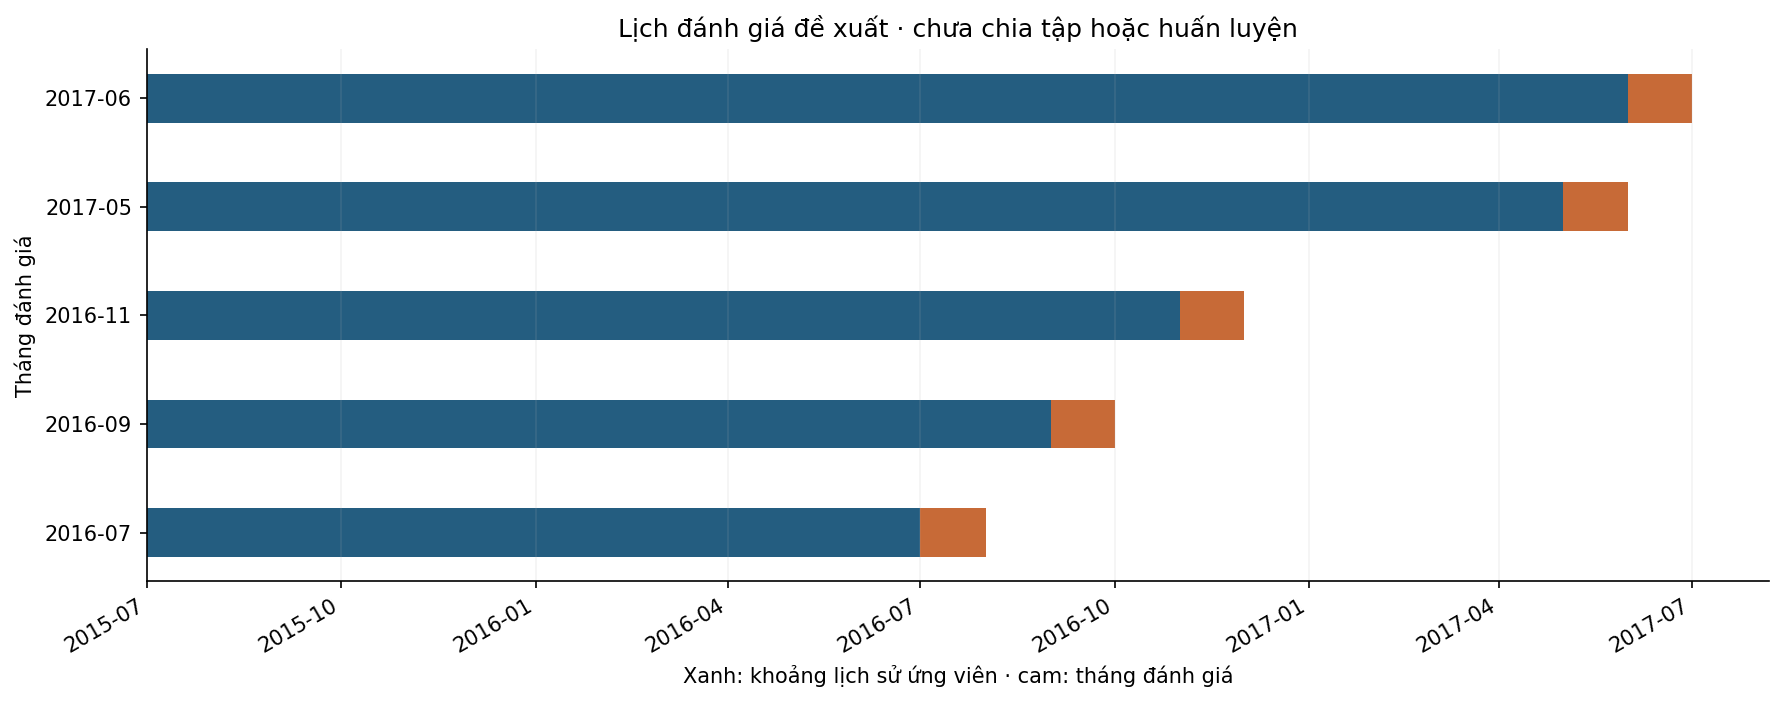

**Quan sát:** các cửa sổ đánh giá dùng thứ tự thời gian và lịch sử mở rộng.

**Phạm vi và cách đọc:** trục là ngày đến, chỉ dùng chẩn đoán hồi cứu. Vùng xanh còn phải lọc kết quả đã hoàn tất trước O theo bảng; không xác nhận đầu vào có tại t0 hoặc booking còn hiệu lực.

### Tiêu chí chấp nhận đặt trước

Các ngưỡng dưới đây là đề xuất nghiên cứu, chưa phải chuẩn phổ quát hoặc kết quả đo. Chốt trước khi huấn luyện. Độ bất định cần phản ánh cấu trúc phụ thuộc của dữ liệu.

**Điều kiện chấp nhận**

| Tiêu chí | Ngưỡng đề xuất | Cách diễn giải |
| --- | --- | --- |
| Khả dụng tại t0 · điều kiện chặn | 0 cột kết quả/đầu vào/cờ thiếu chưa được xác nhận tại t0; 0 nhóm giao tập | Chặn mọi mô hình nếu vi phạm; liên hệ EDA không thay được chứng cứ thời điểm |
| Thứ tự nhãn và hiệu chỉnh | 100% nhãn học/hiệu chỉnh sẵn có trước O; 100% điểm hiệu chỉnh là OOF theo thời gian | HOTEL cần snapshot; EXPEDIA cần timestamp kết quả hoặc quy tắc theo dõi đã xác nhận |
| Chuẩn xác suất tuyệt đối | \|Trung bình xác suất − tỷ lệ nhãn\| ≤2 điểm phần trăm; ECE 10 nhóm đồng số mẫu ≤3 điểm phần trăm | Đề xuất áp dụng từng tháng cuối và mẫu gộp; báo log loss, Brier, AP, ROC-AUC và biểu đồ độ tin cậy |
| Giá trị bổ sung của cây so với LR mạnh | Log loss giảm ≥1% tương đối; cận trên 95% của Δlog loss (cây − LR) <0 | So ghép cặp cùng mẫu và cùng nhánh; nếu không đạt thì chỉ dùng LR nếu LR qua chuẩn tuyệt đối |
| Độ bền | Báo riêng từng tháng, nhóm chính và kịch bản trùng/cơ chế hiển thị | Không có mô hình được chấp nhận nếu không ứng viên nào qua điều kiện bắt buộc |
| Ưu tiên can thiệp | Lift@20% tăng ≥5% tương đối so với LR, cận dưới 95% của Δlift >0 | Ngân sách 20% là đề xuất; bootstrap theo nhóm booking/khách nếu có. Không suy thành hiệu quả giữ chân |

In [10]:
eda.show_section(report, 'design')

## Phụ lục — từ điển và bảng bổ sung

In [11]:
eda.show_section(report, 'appendix')

### Từ điển dữ liệu và kiểu dữ liệu thực tế

Kiểu pandas không đồng nghĩa vai trò thống kê. `agent` và `company` được đọc như số nhưng là ID phân loại. Các cột lịch không phải các phép đo liên tục độc lập. Bảng dưới kiểm kê đủ 32 cột trên toàn bộ dữ liệu.

**Schema, độ đa dạng và missing**

| Cột gốc | Kiểu dữ liệu | Số giá trị khác nhau không thiếu | Số thiếu | Tỷ lệ thiếu (%) | Ý nghĩa | Vai trò và lưu ý | Vai trò | unit | Miền giá trị và căn cứ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| hotel | object | 2 | 0 | 0 | City Hotel / Resort Hotel | Phân khúc; chỉ hai cơ sở gốc, không đại diện toàn ngành | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'City Hotel', 'Resort Hotel' |
| is_canceled | int64 | 2 | 0 | 0 | Nhãn kết quả booking, 0/1 | Target; dữ liệu hiện tại gộp Canceled và No-Show vào 1 | đích | cờ 0/1 | Toàn bảng: np.int64(0), np.int64(1) |
| lead_time | int64 | 479 | 0 | 0 | Số ngày từ lúc nhập booking đến ngày đến | Kiểm tra mốc dự đoán và lịch sử thay đổi ngày đến | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | ngày | Toàn bảng: [0, 737], 479 giá trị phân biệt |
| arrival_date_year | int64 | 3 | 0 | 0 | Năm đến dự kiến | Thời gian; không coi là đại lượng liên tục thông thường | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | thành phần lịch theo tên biến | Toàn bảng: np.int64(2015), np.int64(2016), np.int64(2017) |
| arrival_date_month | object | 12 | 0 | 0 | Tháng đến dự kiến | Thời gian dạng tên tháng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | thành phần lịch theo tên biến | Toàn bảng: 'April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September' |
| arrival_date_week_number | int64 | 53 | 0 | 0 | Tuần của ngày đến | Thời gian, chồng lặp thông tin với ngày/tháng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | thành phần lịch theo tên biến | Toàn bảng: [1, 53], 53 giá trị phân biệt |
| arrival_date_day_of_month | int64 | 31 | 0 | 0 | Ngày trong tháng của ngày đến | Thời gian | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | thành phần lịch theo tên biến | Toàn bảng: [1, 31], 31 giá trị phân biệt |
| stays_in_weekend_nights | int64 | 17 | 0 | 0 | Số đêm cuối tuần đặt/lưu trú | Số đếm; xác minh snapshot | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | đêm | Toàn bảng: [0, 19], 17 giá trị phân biệt |
| stays_in_week_nights | int64 | 35 | 0 | 0 | Số đêm ngày thường đặt/lưu trú | Số đếm; xác minh snapshot | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | đêm | Toàn bảng: [0, 50], 35 giá trị phân biệt |
| adults | int64 | 14 | 0 | 0 | Số người lớn | Kiểm tra 0 và số lượng lớn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | người | Toàn bảng: [0, 55], 14 giá trị phân biệt |
| children | float64 | 5 | 4 | 0.0034 | Số trẻ em | Có missing; không mặc định missing = 0 | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | người | Toàn bảng: np.float64(0.0), np.float64(1.0), np.float64(10.0), np.float64(2.0), np.float64(3.0) |
| babies | int64 | 5 | 0 | 0 | Số em bé | Số đếm | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | người | Toàn bảng: np.int64(0), np.int64(1), np.int64(10), np.int64(2), np.int64(9) |
| meal | object | 5 | 0 | 0 | Gói bữa ăn | Undefined/SC có thể có nghĩa không có gói ăn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'BB', 'FB', 'HB', 'SC', 'Undefined' |
| country | object | 177 | 488 | 0.4087 | Quốc gia nguồn gốc khách | Mã phân loại; có thể cập nhật gần check-in | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 177 giá trị khác nhau; top category tại phụ lục |
| market_segment | object | 8 | 0 | 0 | Phân khúc thị trường | Biến phân loại | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA', 'Undefined' |
| distribution_channel | object | 5 | 0 | 0 | Kênh phân phối | Biến phân loại; có liên hệ market_segment | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'Corporate', 'Direct', 'GDS', 'TA/TO', 'Undefined' |
| is_repeated_guest | int64 | 2 | 0 | 0 | Khách quay lại, 0/1 | Đã tồn tại trong raw; không tạo lại feature | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | cờ 0/1 | Toàn bảng: np.int64(0), np.int64(1) |
| previous_cancellations | int64 | 15 | 0 | 0 | Số booking hủy trước booking hiện tại | Lịch sử; cần xác minh cách chốt thời gian | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | lần/booking/yêu cầu theo tên biến | Toàn bảng: [0, 26], 15 giá trị phân biệt |
| previous_bookings_not_canceled | int64 | 73 | 0 | 0 | Số booking trước không hủy | Lịch sử; cần xác minh cách chốt thời gian | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | lần/booking/yêu cầu theo tên biến | Toàn bảng: [0, 72], 73 giá trị phân biệt |
| reserved_room_type | object | 10 | 0 | 0 | Mã loại phòng đã đặt | Biến phân loại | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L', 'P' |
| assigned_room_type | object | 12 | 0 | 0 | Mã loại phòng được phân | Có thể cập nhật sau đặt; chưa chứng minh có sẵn tại t0 | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P' |
| booking_changes | int64 | 21 | 0 | 0 | Số lần sửa booking đến check-in/hủy | Biến tích lũy; nguy cơ dùng thông tin tương lai | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | lần/booking/yêu cầu theo tên biến | Toàn bảng: [0, 21], 21 giá trị phân biệt |
| deposit_type | object | 3 | 0 | 0 | Trạng thái đặt cọc từ thanh toán | Không mặc định đồng nghĩa chính sách đã biết lúc tạo booking | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'No Deposit', 'Non Refund', 'Refundable' |
| agent | float64 | 333 | 16,340 | 13.6862 | ID đại lý | Phân loại; NULL có thể là không áp dụng, không phải số liên tục | định danh / khóa nhóm, không phải số liên tục | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: [1, 535], 333 giá trị phân biệt |
| company | float64 | 352 | 112,593 | 94.3069 | ID công ty/thực thể trả tiền | Phân loại; NULL có thể là không áp dụng | định danh / khóa nhóm, không phải số liên tục | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: [6, 543], 352 giá trị phân biệt |
| days_in_waiting_list | int64 | 128 | 0 | 0 | Số ngày chờ trước xác nhận | Chỉ biết đầy đủ khi kết thúc chờ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | ngày | Toàn bảng: [0, 391], 128 giá trị phân biệt |
| customer_type | object | 4 | 0 | 0 | Contract / Group / Transient / Transient-Party | Biến phân loại | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'Contract', 'Group', 'Transient', 'Transient-Party' |
| adr | float64 | 8,879 | 0 | 0 | Average Daily Rate, tiền/đêm | Theo nguồn là tổng giao dịch lưu trú / số đêm; xác minh thời điểm và đơn vị | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | tiền/đêm; xác minh đồng tiền của bản CSV | Toàn bảng: [-6.38, 5400], 8879 giá trị phân biệt |
| required_car_parking_spaces | int64 | 5 | 0 | 0 | Số chỗ đỗ xe yêu cầu | Có thể cập nhật theo booking | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | chỗ đỗ xe | Toàn bảng: np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(8) |
| total_of_special_requests | int64 | 6 | 0 | 0 | Số yêu cầu đặc biệt | Có thể cập nhật theo booking | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | lần/booking/yêu cầu theo tên biến | Toàn bảng: np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5) |
| reservation_status | object | 3 | 0 | 0 | Trạng thái cuối: Canceled / Check-Out / No-Show | Kết quả sau sự kiện; rò rỉ nhãn | kết quả / nguy cơ rò rỉ đích | mã/nhãn phân loại, không có đơn vị vật lý | Toàn bảng: 'Canceled', 'Check-Out', 'No-Show' |
| reservation_status_date | object | 926 | 0 | 0 | Ngày thiết lập trạng thái cuối | Kết quả sau sự kiện; không dùng làm đầu vào dự đoán | kết quả / nguy cơ rò rỉ đích | ngày/giờ theo định dạng nguồn; timezone chưa xác minh | Toàn bảng: 926 giá trị khác nhau; top category tại phụ lục |

### Danh mục file, dung lượng và SHA-256

Phiên bản local được xác định bằng các giá trị dưới đây; không suy ngày tải từ ngày sửa file.

... (64 outputs left out)

### Truy vết tóm tắt điều hành

Số liệu tóm tắt được tạo từ cùng bảng/facts dùng xuất báo cáo. Metadata lưu giá trị gốc để đối chiếu, không chép tay số liệu.

**Phát hiện và nguồn trong báo cáo**

| STT | Phát hiện | Khóa mục bằng chứng |
| --- | --- | --- |
| 1 | **Đơn vị và quy mô:** 119,390 booking × 32 cột, chỉ hai cơ sở; không có khóa khách hàng. | dictionary |
| 2 | **Nhãn:** 44,224 hủy/no-show (37.04%); bảng chéo xác nhận nhãn 0 là Check-Out. | quality |
| 3 | **Độ nhạy trùng:** 31,994 dòng trùng; giả định bỏ trùng còn 87,396, tỷ lệ 27.49%. Chưa quyết định xóa. | duplicate_by_hotel |
| 4 | **Khác biệt cơ sở:** City 41.73% so với Resort 27.76%; cần đọc cùng chuẩn hóa phân khúc. | stratification |
| 5 | **Liên hệ và đầu vào:** đã kiểm tra 29 cột ứng viên; cả 32 cột raw có quyết định vai trò. Liên hệ mạnh chưa bảo đảm hợp lệ tại t0. | signal |
| 6 | **Thiết kế đề xuất:** LR có tương tác so với CatBoost trên cùng nhánh hợp lệ; chia theo thời gian, hiệu chỉnh OOF và kiểm tra độ nhạy trùng. Lịch theo tháng đến chỉ là chẩn đoán hồi cứu khi chưa có snapshot. | design |

## Tái lập và kiểm soát phạm vi

In [12]:
eda.show_section(report, 'reproducibility')

Chạy notebook theo thứ tự từ đầu, hoặc chạy `python scripts/build_descriptive_reports.py --dataset HOTEL` tại thư mục gốc. Script chỉ đọc CSV raw, viết báo cáo/biểu đồ và lưu notebook trong notebooks/; không sửa raw, không ghi data/processed, không gọi pipeline huấn luyện. Các thời điểm phân tích dùng Asia/Ho_Chi_Minh. SHA-256 ở danh mục file nhận diện nguồn; số dòng theo CSV parser được đối chiếu với data_lines của file chính. Ngày tải raw chưa được ghi nhận; không suy từ mtime/ctime. Hình lấy mẫu hiển thị dùng seed=42. Script thực thi các cell bằng IPython trong cùng tiến trình và lưu output thật vào notebook; không khởi tạo kernel mạng. Phụ thuộc dựng báo cáo gồm pandas, numpy, scipy, matplotlib, nbformat và IPython; có thể mở notebook bằng Jupyter để Run All.

Phần nghiên cứu bổ sung do scripts/hotel_expedia_research.py tạo từ cùng CSV. V tính từ bảng chéo K×2 không hiệu chỉnh; rank-biserial = 2U/(n1×n0)−1, với U của nhãn 1 và xử lý hòa hạng của SciPy. Không dùng kiểm định giả định các dòng độc lập để khẳng định ý nghĩa thống kê. Thống kê bổ sung Expedia dùng toàn bộ search và các bảng đếm toàn train. Các lịch chia tập chỉ là bảng quy mô, chưa sinh tập học hoặc dự đoán.

Chạy riêng: `python scripts/build_descriptive_reports.py --dataset HOTEL`. Cần package scripts/, pandas, numpy, scipy, matplotlib, nbformat và IPython cùng dữ liệu raw tương ứng. SHA-256 từng CSV ở phụ lục; ngày tải và phiên bản chưa được ghi nhận. Không suy ngày tải từ timestamp file.

**Môi trường thực thi**

| Thành phần | Giá trị |
| --- | --- |
| Python | 3.14.2 |
| pandas | 2.3.3 |
| numpy | 2.4.1 |
| matplotlib | 3.10.8 |
| Phương pháp | Thống kê mô tả, không mô hình |
| Chunk CSV lớn | 250000 |